# Figures for the author response

Recreates Figures R1–R21 from `tables.xlsx` and writes each to `figures/`. Run the setup cell first; the figure cells can then be run in any order.

Requires Python 3 with `pandas`, `numpy`, `matplotlib`, `seaborn` (0.13 or later) and `openpyxl`.

In [23]:
from pathlib import Path
import os, re, sys, subprocess, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


HERE = Path.cwd().resolve()
XLSX = next(q for p in [HERE, *HERE.parents] for q in (p / "tables.xlsx", p / "anonymous_repository" / "tables.xlsx") if q.exists())
FIGS = XLSX.parent / "figures"
FIGS.mkdir(exist_ok=True)

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8985", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
sns.set_theme(context="paper", style="ticks", palette=PAL, rc={
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold",
    "font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "axes.titleweight": "normal", "axes.titlepad": 4, "pdf.fonttype": 42, "ps.fonttype": 42,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.linewidth": 0.6, "axes.labelcolor": INK, "text.color": INK,
    "axes.titlecolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.5,
    "legend.frameon": False, "lines.linewidth": 1.3, "lines.markersize": 4,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.max_open_warning": 0})

SYS = {"medgemma_4b": "MedGemma-4B", "qwen25vl_7b": "Qwen2.5-VL-7B", "qwen25vl_3b": "Qwen2.5-VL-3B",
       "txrv_densenet": "TXRV DenseNet", "txrv_chex": "TXRV (CheXpert-only)", "llava15_7b": "LLaVA-1.5-7B",
       "medgemma_probe": "MedGemma + trained probe", "medgemma_probe_calibrated": "MedGemma + probe (calibrated)"}
HEADLINE = ["medgemma_4b", "qwen25vl_7b", "qwen25vl_3b", "txrv_densenet"]
ALL5 = HEADLINE + ["txrv_chex"]
SYS_COLOR = {**{SYS[s]: c for s, c in zip(ALL5, PAL)}, SYS["llava15_7b"]: MUTED,
             SYS["medgemma_probe"]: PAL[0], SYS["medgemma_probe_calibrated"]: "#7fb0ea"}
MARKERS = ["o", "s", "^", "D", "v"]
ATTR = {"race": "Race", "sex": "Sex", "insurance": "Insurance", "age_group": "Age", "sex_race": "Sex × race"}
RACE = ["White", "Black", "Hispanic", "Asian", "Other"]
AGE = ["18-40", "40-60", "60-80", "80+"]
AGE_TICK = {"18-40": "18–40", "40-60": "40–60", "60-80": "60–80", "80+": "≥80"}
RACE_COLOR = dict(zip(RACE, PAL))
AGE_COLOR = dict(zip(AGE, [PAL[0], PAL[2], PAL[3], PAL[1]]))
RACE_STYLE = {"White": (PAL[0], "o", ""), "Black": (PAL[1], "s", (4, 1.5)), "Hispanic": (PAL[2], "^", (1, 1)),
              "Asian": (PAL[3], "D", (3, 1.25, 1.5, 1.25)), "Other": (PAL[4], "v", (5, 1, 1, 1))}
AGE_STYLE = {"18-40": (PAL[0], "o", ""), "40-60": (PAL[2], "s", (4, 1.5)), "60-80": (PAL[3], "^", (1, 1)),
             "80+": (PAL[1], "D", (3, 1.25, 1.5, 1.25))}
RACE_MARKERS, RACE_DASHES = {g: v[1] for g, v in RACE_STYLE.items()}, {g: v[2] for g, v in RACE_STYLE.items()}
AGE_MARKERS, AGE_DASHES = {g: v[1] for g, v in AGE_STYLE.items()}, {g: v[2] for g, v in AGE_STYLE.items()}
SYS_MARKER = {**{SYS[s]: m for s, m in zip(ALL5, MARKERS)}, SYS["llava15_7b"]: "o",
              SYS["medgemma_probe"]: "o", SYS["medgemma_probe_calibrated"]: "s"}
COV_TICKS, COV_LABELS = [0.2, 0.5, 0.8, 0.95], ["0.2", "0.5", "0.8", "0.95"]
FIG_ID = {"class_mix": "R1",
          "calibration_by_group": "R2",
          "deployment_race": "R3",
          "deployment_error_rates": "R4",
          "temporal_vs_random": "R5",
          "two_sites_age": "R6",
          "error_capture_by_type_and_age": "R7",
          "competing_objectives": "R8",
          "allocation_real_scores": "R9",
          "operating_characteristics": "R10",
          "per_pathology_dgap": "R11",
          "rare_findings_deployment": "R12",
          "null_tests": "R13",
          "added_systems": "R14",
          "task_adaptation": "R15",
          "robustness_ledger": "R16",
          "label_robustness": "R17",
          "token_mass": "R18",
          "confidence_alternatives": "R19",
          "decomposition": "R20",
          "image_blind_controls": "R21"}


META = {"pdf": {"Creator": None, "Producer": None, "CreationDate": None}, "png": {"Software": None}}


_INDEX = pd.read_excel(XLSX, sheet_name="Index")
_SHEET = dict(zip(_INDEX["file"].str.replace(".csv", "", regex=False), _INDEX["sheet"]))


def load(name):
    df = pd.read_excel(XLSX, sheet_name=_SHEET[name])
    df.columns = [c.replace(" ", "_") for c in df.columns]
    return df


def save(fig, name, *args, **kwargs):
    fig = getattr(fig, "figure", fig)
    fname = f"fig{FIG_ID[name]}_{name}"
    fig.savefig(FIGS / f"{fname}.png", metadata=META["png"])
    print(f"saved figures/{fname}.png")


from matplotlib.lines import Line2D
from matplotlib.patches import Patch

LEGEND = dict(loc="upper center", bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=7, handlelength=2.2,
              handletextpad=0.5, columnspacing=1.6, borderaxespad=0.3)


def signed(v, digits=2):
    t = f"{v:+.{digits}f}"
    return f"{0:.{digits}f}" if float(t) == 0 else t.replace("-", "\u2212")


def letter_panels(axes):
    for i, ax in enumerate(axes):
        ax.annotate(chr(97 + i), xy=(0, 1), xycoords="axes fraction", xytext=(-20, 7), textcoords="offset points",
                    fontsize=9, fontweight="bold", ha="left", va="bottom")


def bottom_legend(fig, handles, ncol=None):
    fig = getattr(fig, "figure", fig)
    for ax in fig.axes:
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    for lg in list(fig.legends):
        lg.remove()
    fig.tight_layout()
    ncol = ncol or len(handles)
    rows = -(-len(handles) // ncol)
    handles = [handles[r * ncol + c] for c in range(ncol) for r in range(rows) if r * ncol + c < len(handles)]
    fig.legend(handles=handles, ncol=ncol, **LEGEND)


def line_key(label, color, marker=None, dash="", lw=1.3):
    kw = dict(color=color, lw=lw, marker=marker, ms=4, label=label)
    if dash:
        kw["dashes"] = dash
    return Line2D([], [], **kw)


def dot_key(label, color, marker="o", filled=True):
    return Line2D([], [], ls="", marker=marker, ms=4.5, color=color, mec=color, mfc=color if filled else SURFACE, label=label)


def box_key(label, color):
    return Patch(facecolor=color, edgecolor="none", label=label)


RACE_KEYS = [line_key(g, c, m, d) for g, (c, m, d) in RACE_STYLE.items()]
AGE_KEYS = [line_key(f"{AGE_TICK[g]} years", c, m, d) for g, (c, m, d) in AGE_STYLE.items()]


def system_keys(systems, line=False):
    names = [SYS[s] for s in systems]
    return [line_key(n, SYS_COLOR[n], SYS_MARKER[n]) if line else dot_key(n, SYS_COLOR[n], SYS_MARKER[n]) for n in names]


def filled_keys(filled_means, open_means):
    return [dot_key(filled_means, INK2), dot_key(open_means, INK2, filled=False)]


def quadrant_scatter(data, **kw):
    ax = plt.gca()
    lim = 1.1 * np.nanmax(np.abs(data[["original", "alternative"]].to_numpy(float)))
    ax.fill_between([0, lim], 0, lim, color="#e8f2eb", zorder=0, lw=0)
    ax.fill_between([-lim, 0], -lim, 0, color="#e8f2eb", zorder=0, lw=0)
    ax.plot([-lim, lim], [-lim, lim], ls=":", color=MUTED, lw=0.8, zorder=1)
    for name, sub in data.groupby("system", sort=False, observed=True):
        on = sub["significant"].astype(bool)
        mk = SYS_MARKER[name]
        ax.scatter(sub.original[on], sub.alternative[on], marker=mk, color=SYS_COLOR[name], s=18, zorder=3, label=name)
        ax.scatter(sub.original[~on], sub.alternative[~on], marker=mk, facecolor=SURFACE, edgecolor=SYS_COLOR[name], s=14, lw=0.9, zorder=3)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.axhline(0, color=MUTED, lw=0.5); ax.axvline(0, color=MUTED, lw=0.5); ax.grid(False)


SIG = load("R0_paper_random_null_25cells")[["system", "attribute", "outside_null"]].rename(columns={"outside_null": "significant"})
FIND = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion", "Pneumonia", "Pneumothorax", "POOLED"]
print(f"tables: {XLSX.name} ({len(_SHEET)} tables); figures are written to {FIGS.name}/")

tables: tables.xlsx (55 tables); figures are written to figures/


## Figure R1. Class mix among accepted evaluations under the original and reversed confidence ranking

(a–d) Label prevalence and (e–h) positive-prediction rate among accepted evaluations, by race, as a function of within-group coverage *c*; solid lines, original ranking; dashed lines, reversed ranking. (i–l) Resulting Δgap for race. The dotted vertical line marks *c* = 0.2. For MedGemma-4B and Qwen2.5-VL-7B the two rankings shift prevalence in opposite directions, yet both narrow the gap at *c* = 0.2; class mix therefore does not account for the effect. For Qwen2.5-VL-3B, reversing the ranking reverses the sign of Δgap.

saved figures/figR1_class_mix.png


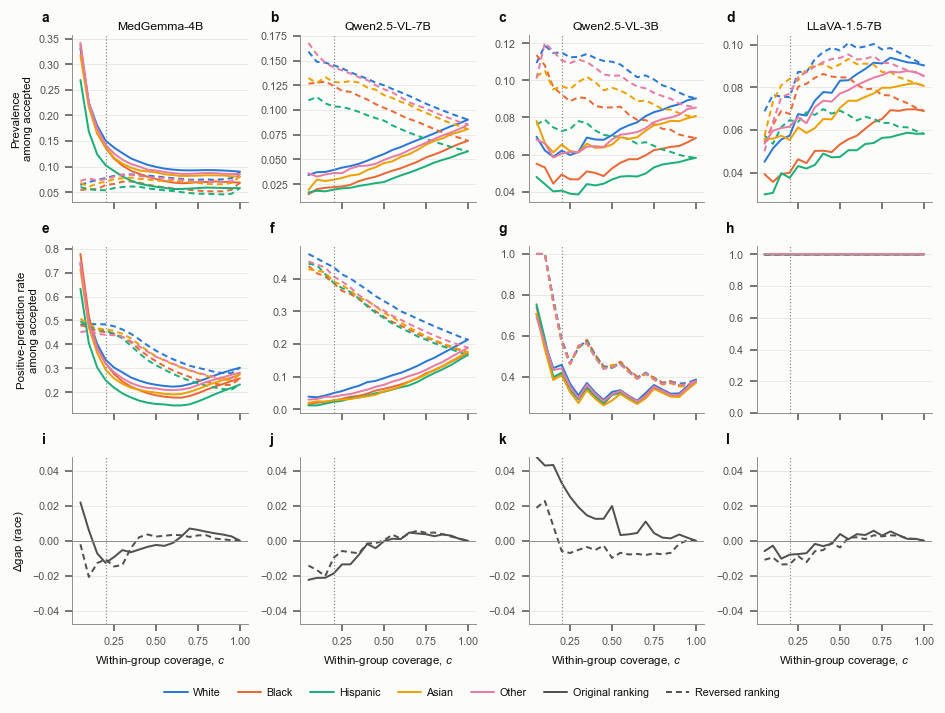

In [24]:
cm = load("R9c_class_mix_vs_coverage").query("attribute == 'race'")
CM_SYS = ["medgemma_4b", "qwen25vl_7b", "qwen25vl_3b", "llava15_7b"]
gap = cm.groupby(["system", "ranking", "coverage"]).selective_risk.agg(lambda v: v.max() - v.min()).rename("gap").reset_index()
full = gap[gap.coverage == 1.0].set_index(["system", "ranking"]).gap
gap["dgap"] = [r.gap - full[(r.system, r.ranking)] for r in gap.itertuples()]
RANK = dict(style="ranking", style_order=["original", "reversed"], dashes=["", (3, 2)], legend=False)
fig, axes = plt.subplots(3, 4, figsize=(8.6, 6.2), sharex=True)
for j, s in enumerate(CM_SYS):
    for i, col in enumerate(["prevalence", "pred_pos_rate"]):
        sns.lineplot(data=cm[cm.system == s], x="coverage", y=col, hue="group", hue_order=RACE, palette=RACE_COLOR, ax=axes[i, j], **RANK)
    sns.lineplot(data=gap[gap.system == s], x="coverage", y="dgap", color=INK2, ax=axes[2, j], **RANK)
    axes[2, j].axhline(0, color=MUTED, lw=0.6)
    axes[0, j].set_title(SYS[s])
for ax in axes.flat:
    ax.axvline(0.2, color=MUTED, ls=":", lw=0.8)
    ax.ticklabel_format(axis="y", useOffset=False)
    ax.set_xlabel(""); ax.set_ylabel("")
axes[1, 3].set_ylim(0, 1.05)
lim = 1.1 * gap[gap.coverage >= 0.1].dgap.abs().max()
for ax in axes[2]:
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("Within-group coverage, $c$")
axes[0, 0].set_ylabel("Prevalence\namong accepted")
axes[1, 0].set_ylabel("Positive-prediction rate\namong accepted")
axes[2, 0].set_ylabel(r"$\Delta$gap (race)")
letter_panels(axes.flat)
bottom_legend(fig, [line_key(r, RACE_COLOR[r]) for r in RACE]
           + [line_key("Original ranking", INK2), line_key("Reversed ranking", INK2, dash=(3, 2))])
plot = pd.concat([cm.melt(id_vars=["system", "group", "ranking", "coverage"], value_vars=["prevalence", "pred_pos_rate"], var_name="metric"),
                  gap.assign(group="all", metric="race gap change", value=gap.dgap)[["system", "group", "ranking", "coverage", "metric", "value"]]],
                 ignore_index=True).assign(system=lambda x: x.system.map(SYS))
save(fig, "class_mix", plot, ["X8Ma", "4Avf"], bundle_name="figR1_class_mix")

## Figure R2. Calibration by group

Error rate within each decile of pooled confidence, by race (a–d); the dashed black line is all patients. Group curves that coincide with the pooled curve indicate distribution shift; curves that separate from it indicate calibration disparity.

saved figures/figR2_calibration_by_group.png


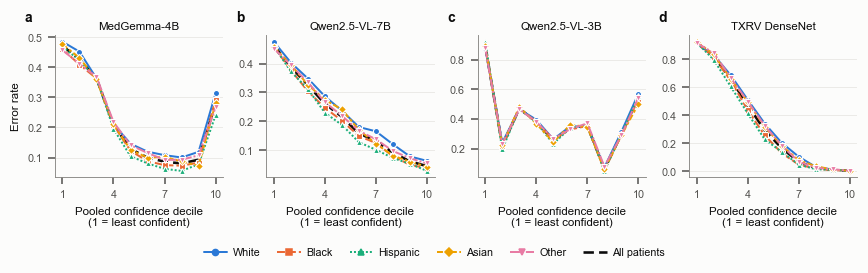

In [25]:
cb = load("R9f_calibration_by_group")
plot = cb.assign(system=cb.system.map(SYS))
g = sns.relplot(data=plot[plot.group != "pooled"], kind="line", x="decile", y="error_rate", hue="group", hue_order=RACE,
                palette=RACE_COLOR, style="group", style_order=RACE, markers=RACE_MARKERS, dashes=RACE_DASHES, col="system",
                col_order=[SYS[s] for s in HEADLINE], height=2.2, aspect=0.9, facet_kws=dict(sharey=False), legend=False)
for ax, s in zip(g.axes.flat, HEADLINE):
    p = plot[(plot.system == SYS[s]) & (plot.group == "pooled")]
    ax.plot(p.decile, p.error_rate, color=INK, lw=1.7, dashes=(4, 2), zorder=1)
g.set_titles("{col_name}")
g.set(xticks=[1, 4, 7, 10])
g.set_axis_labels("Pooled confidence decile\n(1 = least confident)", "Error rate")
letter_panels(g.axes.flat)
bottom_legend(g, RACE_KEYS + [line_key("All patients", INK, dash=(4, 2), lw=1.7)])
save(g, "calibration_by_group", plot, ["X8Ma", "4Avf"], bundle_name="figR3_calibration_by_group")

## Figure R3. Deployment with a single group-blind threshold

One abstention threshold is fitted on a patient-level calibration half at natural prevalence and applied unchanged to the held-out half. (a–d) Coverage of each race group relative to overall coverage, in percentage points. (e–h) Selective risk of each race group. At *c* = 0.2, TXRV DenseNet covers 15.2–25.8% of the race groups while its selective-risk gap is 0.007.

saved figures/figR3_deployment_race.png


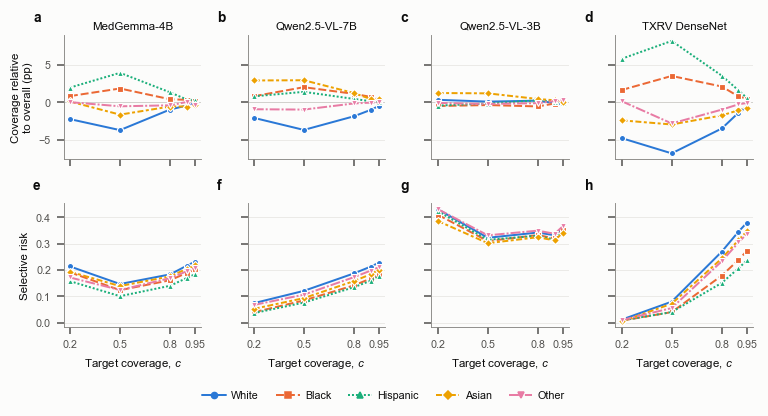

In [26]:
d = load("R1a_deployment_per_group").query("attribute == 'race' and system in @HEADLINE").copy()
d["coverage − overall (pp)"] = 100 * (d.induced_coverage - d.achieved_overall)
d["selective risk"] = d.selective_risk
plot = (d.assign(system=d.system.map(SYS))
         .melt(id_vars=["system", "target_coverage", "group"], value_vars=["coverage − overall (pp)", "selective risk"],
               var_name="metric", value_name="value"))
g = sns.relplot(data=plot, kind="line", x="target_coverage", y="value", row="metric", col="system",
                col_order=[SYS[s] for s in HEADLINE], hue="group", style="group", hue_order=RACE, style_order=RACE,
                palette=RACE_COLOR, markers=RACE_MARKERS, dashes=RACE_DASHES, height=1.75, aspect=1.0,
                facet_kws=dict(sharey="row", margin_titles=False), legend=False)
g.set_titles("{col_name}")
for ax in g.axes[1]:
    ax.set_title("")
for ax in g.axes[0]:
    ax.axhline(0, color=MUTED, lw=0.6, zorder=0)
g.set(xticks=COV_TICKS, xticklabels=COV_LABELS)
g.set_xlabels("Target coverage, $c$")
g.axes[0, 0].set_ylabel("Coverage relative\nto overall (pp)")
g.axes[1, 0].set_ylabel("Selective risk")
letter_panels(g.axes.flat)
bottom_legend(g, RACE_KEYS)
save(g, "deployment_race", plot, ["general", "p92Y", "dYNd"])

## Figure R4. False-negative and false-positive rates under deployment

False-negative (a–d) and false-positive (e–h) rates among accepted evaluations, by race, under the deployment of Figure R3.

saved figures/figR4_deployment_error_rates.png


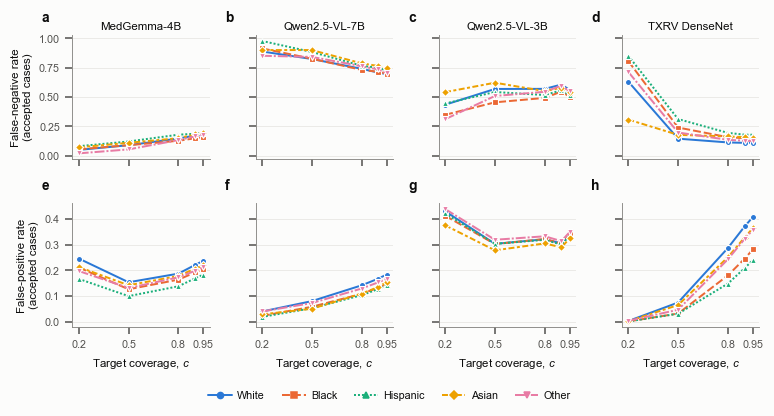

In [27]:
d = load("R1a_deployment_per_group").query("attribute == 'race' and system in @HEADLINE").copy()
d["false-negative rate"], d["false-positive rate"] = d.fnr, d.fpr
plot = (d.assign(system=d.system.map(SYS))
         .melt(id_vars=["system", "target_coverage", "group"], value_vars=["false-negative rate", "false-positive rate"],
               var_name="metric", value_name="value"))
g = sns.relplot(data=plot, kind="line", x="target_coverage", y="value", row="metric", col="system",
                col_order=[SYS[s] for s in HEADLINE], hue="group", style="group", hue_order=RACE, style_order=RACE,
                palette=RACE_COLOR, markers=RACE_MARKERS, dashes=RACE_DASHES, height=1.75, aspect=1.0,
                facet_kws=dict(sharey="row", margin_titles=False), legend=False)
g.set_titles("{col_name}")
for ax in g.axes[1]:
    ax.set_title("")
g.set(xticks=COV_TICKS, xticklabels=COV_LABELS)
g.set_xlabels("Target coverage, $c$")
g.axes[0, 0].set_ylabel("False-negative rate\n(accepted cases)")
g.axes[1, 0].set_ylabel("False-positive rate\n(accepted cases)")
letter_panels(g.axes.flat)
bottom_legend(g, RACE_KEYS)
save(g, "deployment_error_rates", plot, ["general", "p92Y", "dYNd"])

## Figure R5. Temporal deployment

Race (a, c) and age (b, d) selective-risk gaps at *c* = 0.8 (a, b) and *c* = 0.9 (c, d). Open circles: random patient split, with the range over five random seeds (race only). Filled squares: threshold fitted on studies from 2010–2014, frozen, and deployed on 2015–2018, with the range over five cut points.

saved figures/figR5_temporal_vs_random.png


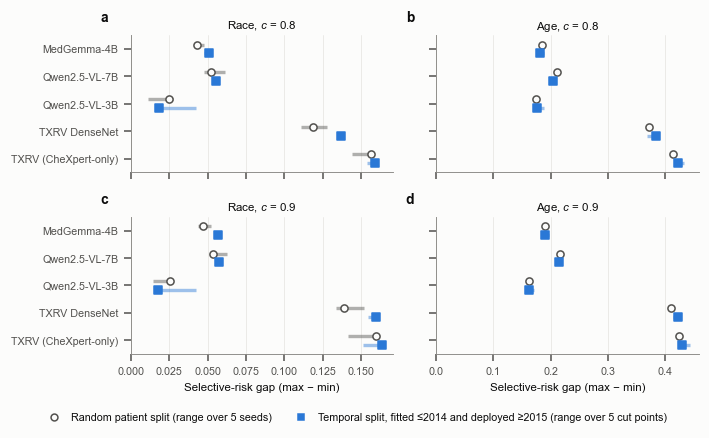

In [28]:
spr = load("R12a_temporal_deployment_spreads")
seeds = load("R1d_deployment_5_seed_stability")
cut = load("R12c_temporal_cutpoint_sensitivity")
SPLITS = {"random": "Random patient split (range over 5 seeds)", "temporal": "Temporal split, fitted ≤2014 and deployed ≥2015 (range over 5 cut points)"}
rows = []
for c in (0.8, 0.9):
    for att in ("race", "age_group"):
        for s in ALL5:
            for key, lab in SPLITS.items():
                v = spr[(spr.system == s) & (spr.attribute == att) & (spr.target_coverage == c) & spr.split.str.startswith(key)].risk_gap.item()
                lo = hi = np.nan
                if key == "random" and att == "race":
                    q = seeds[(seeds.system == s) & (seeds.target_coverage == c)]
                    lo, hi = q.risk_gap_min.item(), q.risk_gap_max.item()
                if key == "temporal":
                    k = cut[(cut.system == s) & (cut.coverage == c)][f"{att}_risk_gap"]
                    lo, hi = k.min(), k.max()
                rows.append(dict(coverage=f"$c$ = {c}", attribute=ATTR[att], system=SYS[s], split=lab,
                                 risk_gap=v, range_lo=lo, range_hi=hi))
tv = pd.DataFrame(rows)


def ranged_points(data, **kw):
    ax = plt.gca()
    order = [SYS[s] for s in ALL5]
    for lab, off, marker, face, col in [(SPLITS["random"], -0.16, "o", SURFACE, INK2), (SPLITS["temporal"], 0.16, "s", PAL[0], PAL[0])]:
        x = data[data.split == lab].set_index("system").loc[order]
        y = np.arange(len(order)) + off
        ax.hlines(y, x.range_lo, x.range_hi, color=col, alpha=0.45, lw=2.2)
        ax.scatter(x.risk_gap, y, s=22, marker=marker, facecolor=face, edgecolor=col, lw=1, zorder=3, label=lab)
    ax.set_yticks(range(len(order)), order)
    ax.set_ylim(len(order) - 0.5, -0.5)
    ax.grid(True, axis="x"); ax.grid(False, axis="y")


g = sns.FacetGrid(tv, row="coverage", col="attribute", sharex="col", height=1.85, aspect=1.75)
g.map_dataframe(ranged_points)
g.set_titles("{col_name}, {row_name}")
g.set_axis_labels("Selective-risk gap (max − min)", "")
for ax in g.axes.flat:
    ax.set_xlim(left=0)
letter_panels(g.axes.flat)
bottom_legend(g, [dot_key(SPLITS["random"], INK2, "o", filled=False), dot_key(SPLITS["temporal"], PAL[0], "s")])
save(g, "temporal_vs_random", tv, ["general", "p92Y"])

## Figure R6. Deployment at two sites, by age

Coverage relative to overall coverage (a–d) and selective risk (e–h) by age group under the held-out global-threshold procedure at MIMIC-CXR (a, b, e, f) and NIH ChestX-ray14 (c, d, g, h; 9,301 patients, 2.3% prevalence).

saved figures/figR6_two_sites_age.png


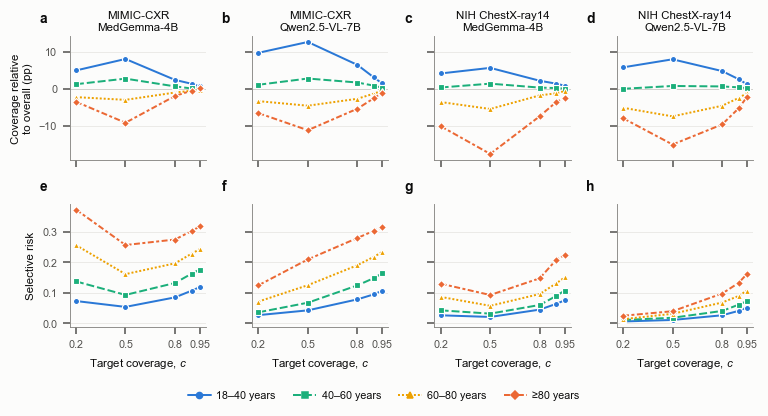

In [29]:
m = (load("R1a_deployment_per_group").query("attribute == 'age_group' and system in ['medgemma_4b', 'qwen25vl_7b']")
       .assign(site="MIMIC-CXR", overall=lambda x: x.achieved_overall))
n = load("R2b_NIH_deployment_per_group").query("attribute == 'age_group'").assign(site="NIH ChestX-ray14", overall=lambda x: x.achieved)
d = pd.concat([m, n], ignore_index=True)
d["panel"] = d.site + "\n" + d.system.map(SYS)
d["coverage − overall (pp)"] = 100 * (d.induced_coverage - d.overall)
d["selective risk"] = d.selective_risk
plot = d.melt(id_vars=["panel", "site", "system", "target_coverage", "group"],
              value_vars=["coverage − overall (pp)", "selective risk"], var_name="metric", value_name="value")
panels = [f"{site}\n{SYS[s]}" for site in ["MIMIC-CXR", "NIH ChestX-ray14"] for s in ["medgemma_4b", "qwen25vl_7b"]]
g = sns.relplot(data=plot, kind="line", x="target_coverage", y="value", row="metric", col="panel", col_order=panels,
                hue="group", style="group", hue_order=AGE, style_order=AGE, palette=AGE_COLOR, markers=AGE_MARKERS,
                dashes=AGE_DASHES, height=1.75, aspect=1.0, facet_kws=dict(sharey="row", margin_titles=False), legend=False)
g.set_titles("{col_name}")
for ax in g.axes[1]:
    ax.set_title("")
for ax in g.axes[0]:
    ax.axhline(0, color=MUTED, lw=0.6, zorder=0)
g.set(xticks=COV_TICKS, xticklabels=COV_LABELS)
g.set_xlabels("Target coverage, $c$")
g.axes[0, 0].set_ylabel("Coverage relative\nto overall (pp)")
g.axes[1, 0].set_ylabel("Selective risk")
letter_panels(g.axes.flat)
bottom_legend(g, AGE_KEYS)
save(g, "two_sites_age", plot, ["general", "p92Y", "dYNd"])

## Figure R7. Errors referred to the clinician, by error type and age

Proportion of false positives (a) and false negatives (b) referred to the clinician by abstention, by age group, under the temporal deployment at *c* = 0.8. Error bars: 95% patient-bootstrap confidence intervals.

saved figures/figR7_error_capture_by_type_and_age.png


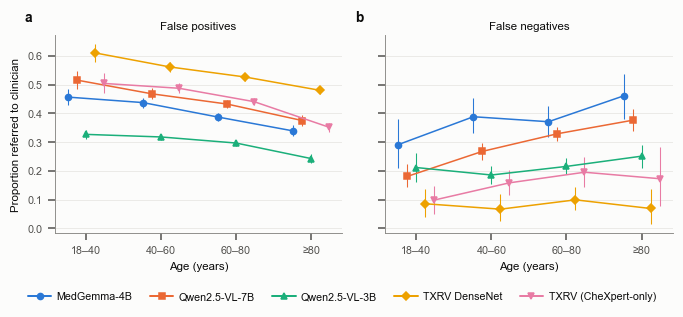

In [30]:
cap = load("R13a_error_capture_by_type_and_age").query("split == 'temporal' and coverage == 0.8")
parts = []
for kind, lab in [("FP", "False positives"), ("FN", "False negatives")]:
    parts.append(cap.assign(error_type=lab, capture=cap[f"{kind}_capture"], ci_lo=cap[f"{kind}_lo"], ci_hi=cap[f"{kind}_hi"]))
plot = pd.concat(parts, ignore_index=True)[["error_type", "system", "age_group", "capture", "ci_lo", "ci_hi", "patients", "n_FN", "n_FP"]]
plot["system"] = plot.system.map(SYS)


def dodged_ci(data, **kw):
    ax = plt.gca()
    order = [SYS[s] for s in ALL5]
    for off, name, mk in zip(np.linspace(-0.24, 0.24, len(order)), order, MARKERS):
        x = data[data.system == name].set_index("age_group").loc[AGE]
        ax.errorbar(np.arange(len(AGE)) + off, x.capture, yerr=[x.capture - x.ci_lo, x.ci_hi - x.capture],
                    color=SYS_COLOR[name], marker=mk, ms=4, lw=1, elinewidth=0.7, label=name)
    ax.set_xticks(range(len(AGE)), [AGE_TICK[a] for a in AGE])


g = sns.FacetGrid(plot, col="error_type", height=2.6, aspect=1.2)
g.map_dataframe(dodged_ci)
g.set_titles("{col_name}")
g.set_axis_labels("Age (years)", "Proportion referred to clinician")
letter_panels(g.axes.flat)
bottom_legend(g, system_keys(ALL5, line=True))
save(g, "error_capture_by_type_and_age", plot, ["p92Y"])

## Figure R8. Competing fairness objectives

Selective risk (a), false-negative rate (b), false-positive rate (c) and residual burden (d; unflagged errors per 1,000 evaluations, *c*<sub>g</sub>*R*<sub>g</sub>) by race for TXRV DenseNet under deployment at *c* = 0.8. The outlined bar marks the worst-served group under each objective.

saved figures/figR8_competing_objectives.png


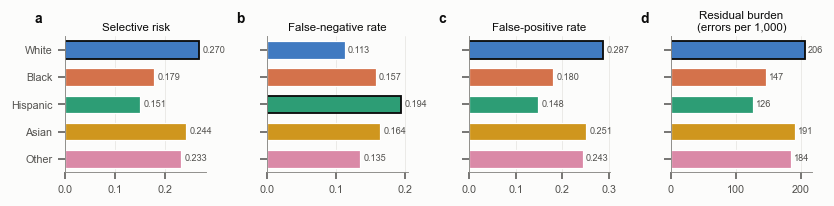

In [31]:
x = load("R1a_deployment_per_group").query("system == 'txrv_densenet' and attribute == 'race' and target_coverage == 0.8")
OBJ = {"selective_risk": "Selective risk", "fnr": "False-negative rate", "fpr": "False-positive rate",
       "unflagged_per_1000": "Residual burden\n(errors per 1,000)"}
plot = x.melt(id_vars="group", value_vars=list(OBJ), var_name="objective", value_name="value")
plot["objective"] = plot.objective.map(OBJ)
g = sns.catplot(data=plot, kind="bar", y="group", x="value", col="objective", col_order=list(OBJ.values()), order=RACE,
                hue="group", hue_order=RACE, palette=RACE_COLOR, sharex=False, height=1.9, aspect=1.0, width=0.65, legend=False)
g.set_titles("{col_name}")
g.set_axis_labels("", "")
for ax in g.axes.flat:
    bars = [b for c in ax.containers for b in c]
    worst = max(bars, key=lambda b: b.get_width())
    worst.set_edgecolor(INK); worst.set_linewidth(1.2)
    big = worst.get_width() > 1
    for c in ax.containers:
        ax.bar_label(c, fmt="%.0f" if big else "%.3f", padding=2, fontsize=6, color=INK2)
    ax.grid(True, axis="x"); ax.grid(False, axis="y")
letter_panels(g.axes.flat)
g.figure.tight_layout()
save(g, "competing_objectives", plot, ["p92Y"])

## Figure R9. Coverage allocation with real confidence scores

Held-out data, five splits, 20 system × attribute cells. (a) Share of the equal-coverage selective-risk gap that each policy closes and (b) change in aggregate selective risk relative to equal within-group coverage; lines are medians and bands interquartile ranges. (c) Number of cells in which the Proposition 2 allocation is feasible, i.e. requires no group coverage above 100%.

saved figures/figR9_allocation_real_scores.png


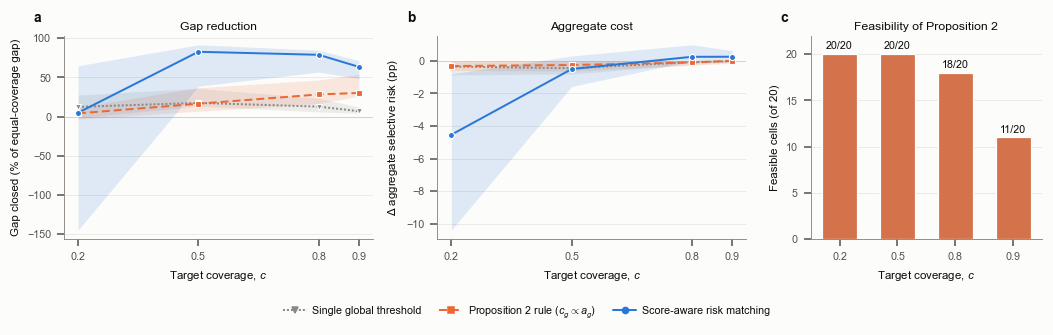

In [32]:
w = load("R3b_allocation_real_scores_wide").query("score == 'model' and system != 'llava15_7b'")
POL = {"global": "Single global threshold", "prop": r"Proposition 2 rule ($c_g \propto a_g$)", "riskmatch": "Score-aware risk matching"}
plot = pd.concat([w.assign(policy=lab, gap_closed_pct=100 * w[f"gapcut_{k}"], cost_pp=100 * w[f"cost_vs_equal_{k}"])
                  for k, lab in POL.items()], ignore_index=True)[["system", "attribute", "coverage", "policy", "gap_closed_pct", "cost_pp"]]
fig, axes = plt.subplots(1, 3, figsize=(9.6, 2.7), gridspec_kw=dict(width_ratios=[1, 1, 0.75]))
kw = dict(x="coverage", hue="policy", style="policy", hue_order=list(POL.values()), style_order=list(POL.values()),
          palette=[MUTED, PAL[1], PAL[0]], markers=["v", "s", "o"], dashes=[(1, 1), (4, 2), ""],
          estimator="median", errorbar=("pi", 50), err_kws=dict(alpha=0.14, lw=0))
sns.lineplot(data=plot, y="gap_closed_pct", ax=axes[0], **kw)
sns.lineplot(data=plot, y="cost_pp", ax=axes[1], legend=False, **kw)
axes[0].set(ylabel="Gap closed (% of equal-coverage gap)", title="Gap reduction")
axes[1].set(ylabel=r"$\Delta$ aggregate selective risk (pp)", title="Aggregate cost")
for ax in axes[:2]:
    ax.axhline(0, color=MUTED, lw=0.6, zorder=0)
    ax.set_xticks(sorted(plot.coverage.unique()))
    ax.set_xlabel("Target coverage, $c$")
feas = (load("R3a_allocation_real_scores_summary").query("score == 'model' and system != 'llava15_7b' and policy == 'prop'")
          .groupby("coverage").prop_feasible.agg(["sum", "size"]).reset_index())
sns.barplot(data=feas, x="coverage", y="sum", color=PAL[1], width=0.6, ax=axes[2])
axes[2].bar_label(axes[2].containers[0], labels=[f"{a}/{b}" for a, b in zip(feas["sum"], feas["size"])], fontsize=7, padding=2)
axes[2].set(ylim=(0, 22), yticks=range(0, 21, 5), xlabel="Target coverage, $c$", ylabel="Feasible cells (of 20)", title="Feasibility of Proposition 2")
letter_panels(axes)
bottom_legend(fig, [line_key(lab, col, mk, d) for lab, col, mk, d in
                 zip(POL.values(), [MUTED, PAL[1], PAL[0]], ["v", "s", "o"], [(1, 1), (4, 2), ""])])
save(fig, "allocation_real_scores", plot, ["general", "p92Y", "dYNd", "4Avf"])

## Figure R10. Operating characteristics

Sensitivity (a), specificity (b), balanced error (c), positive-prediction rate (d), detection AUROC (e) and failure-prediction AUROC (f) at the paper's decision rule. Dotted lines mark chance (0.5). LLaVA-1.5-7B answers *yes* on almost every evaluation.

saved figures/figR10_operating_characteristics.png


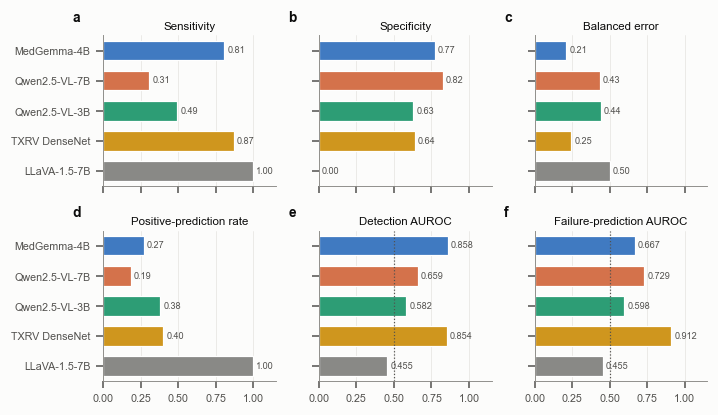

In [33]:
oc = load("R7a_operating_characteristics_incl_llava")
MET = {"sensitivity": "Sensitivity", "specificity": "Specificity", "balanced_error": "Balanced error",
       "pos_rate": "Positive-prediction rate", "auroc": "Detection AUROC", "fail_auroc": "Failure-prediction AUROC"}
plot = oc.melt(id_vars="system", value_vars=list(MET), var_name="metric")
plot = plot.assign(metric=plot.metric.map(MET), system=plot.system.map(SYS))
order = [SYS[s] for s in HEADLINE + ["llava15_7b"]]
g = sns.catplot(data=plot, kind="bar", y="system", x="value", col="metric", col_order=list(MET.values()), order=order,
                hue="system", hue_order=order, palette=SYS_COLOR, col_wrap=3, height=1.9, aspect=1.15, width=0.65, legend=False)
g.set_titles("{col_name}")
g.set_axis_labels("", "")
g.set(xlim=(0, 1.15))
for ax in g.axes.flat:
    auc = "AUROC" in ax.get_title()
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f" if auc else "%.2f", padding=2, fontsize=6, color=INK2)
    if auc:
        ax.axvline(0.5, color=INK2, ls=":", lw=0.8)
    ax.grid(True, axis="x"); ax.grid(False, axis="y")
letter_panels(g.axes.flat)
g.figure.tight_layout()
save(g, "operating_characteristics", plot, ["dYNd"])

## Figure R11. Results for each pathology

Δgap for race by finding at *c* = 0.2 (a) and *c* = 0.8 (b); red, the gap widens; blue, it narrows.

saved figures/figR11_per_pathology_dgap.png


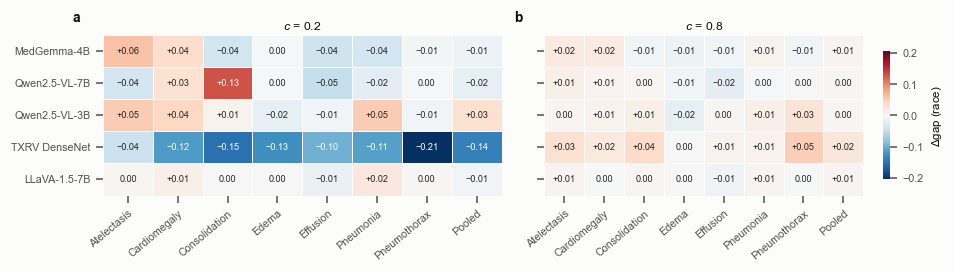

In [34]:
pp = load("R8b_per_pathology_dgap")
FIND = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion", "Pneumonia", "Pneumothorax", "POOLED"]
rows = [s for s in HEADLINE + ["llava15_7b"] if s in set(pp.system)]
v = np.nanmax(np.abs(pp[["dgap_c02", "dgap_c08"]].to_numpy()))
fig, axes = plt.subplots(1, 2, figsize=(8.8, 2.5), sharey=True)
for ax, (col, title) in zip(axes, [("dgap_c02", "$c$ = 0.2"), ("dgap_c08", "$c$ = 0.8")]):
    mat = (pp.pivot(index="system", columns="finding", values=col).loc[rows, FIND]
             .rename(index=SYS, columns={"POOLED": "Pooled", "Pleural Effusion": "Effusion"}))
    sns.heatmap(mat, ax=ax, cmap="RdBu_r", center=0, vmin=-v, vmax=v, annot=mat.map(signed), fmt="", annot_kws=dict(size=6),
                linewidths=0.6, linecolor=SURFACE, cbar=ax is axes[1], cbar_kws=dict(label=r"$\Delta$gap (race)", shrink=0.8))
    ax.set(title=title, xlabel="", ylabel="")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
    ax.grid(False)
letter_panels(axes)
fig.tight_layout()
save(fig, "per_pathology_dgap", pp, ["dYNd"])

## Figure R12. Pathology-level disparities under deployment

Race selective-risk gap (a) and false-negative-rate gap (b) by finding under the held-out global threshold at *c* = 0.8.

saved figures/figR12_rare_findings_deployment.png


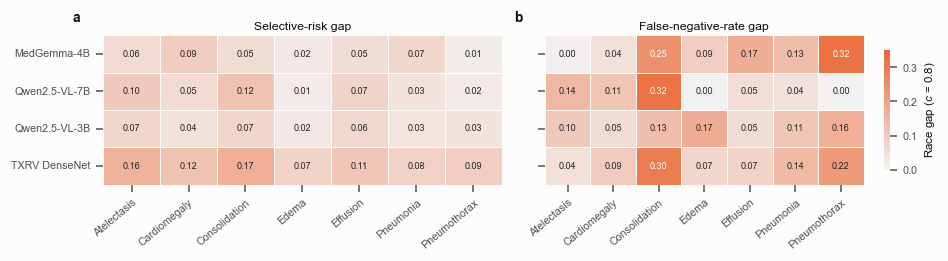

In [35]:
pf = load("R1f_deployment_per_pathology").query("target_coverage == 0.8")
FIND7 = FIND[:-1]
fig, axes = plt.subplots(1, 2, figsize=(8.8, 2.4), sharey=True)
for ax, (col, title) in zip(axes, [("risk_gap", "Selective-risk gap"), ("fnr_gap", "False-negative-rate gap")]):
    mat = (pf.pivot(index="system", columns="finding", values=col).loc[HEADLINE, FIND7]
             .rename(index=SYS, columns={"Pleural Effusion": "Effusion"}))
    sns.heatmap(mat, ax=ax, cmap=sns.light_palette(PAL[1], as_cmap=True), vmin=0, vmax=0.35, annot=True, fmt=".2f",
                annot_kws=dict(size=6), linewidths=0.6, linecolor=SURFACE, cbar=ax is axes[1],
                cbar_kws=dict(label="Race gap ($c$ = 0.8)", shrink=0.8))
    ax.set(title=title, xlabel="", ylabel="")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
    ax.grid(False)
letter_panels(axes)
fig.tight_layout()
save(fig, "rare_findings_deployment", pf, ["dYNd"])

## Figure R13. Tests against chance

(a) Number of the 20 system × attribute cells beyond the random-score null in 300 draws of a joint null that preserves patient-level dependence; the vertical line marks the observed count. (b) Cells beyond the per-cell null at each coverage.

saved figures/figR13_null_tests.png


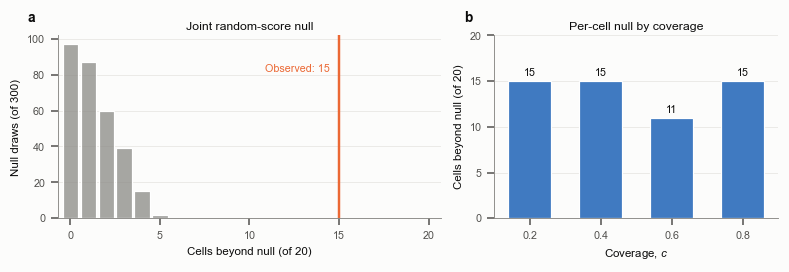

In [36]:
draws = load("R11b_joint_null_draws")
obs = load("R11a_joint_null_count").iloc[0]
sweep = load("R11c_coverage_sweep_counts")
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5), gridspec_kw=dict(width_ratios=[1.35, 1]))
sns.histplot(data=draws, x="count20", discrete=True, color=MUTED, shrink=0.85, ax=axes[0])
axes[0].axvline(obs.observed, color=PAL[1], lw=1.6)
axes[0].annotate(f"Observed: {obs.observed:.0f}", xy=(obs.observed, axes[0].get_ylim()[1] * 0.8),
                 xytext=(-6, 0), textcoords="offset points", ha="right", color=PAL[1], fontsize=7)
axes[0].set(xlim=(-0.7, 20.7), xticks=range(0, 21, 5), xlabel="Cells beyond null (of 20)", ylabel="Null draws (of 300)",
            title="Joint random-score null")
sns.barplot(data=sweep, x="coverage", y="cells_beyond_null_of_20_four_systems", color=PAL[0], width=0.6, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fontsize=7, padding=2)
axes[1].set(ylim=(0, 20), yticks=range(0, 21, 5), xlabel="Coverage, $c$", ylabel="Cells beyond null (of 20)", title="Per-cell null by coverage")
letter_panels(axes)
fig.tight_layout()
save(fig, "null_tests", pd.concat([draws.assign(panel="joint null draws"), sweep.assign(panel="coverage sweep")], ignore_index=True), ["general", "dYNd"])

## Figure R14. Added systems

Δgap by attribute at *c* = 0.2 (a) and *c* = 0.8 (b) for TXRV trained on CheXpert only and for MedGemma-4B with a logistic probe trained on 20,000 patients outside the evaluation cohort (class-balanced and natural-prevalence variants). Grey bars: 95% range of 300 random selection scores; filled markers lie beyond it.

saved figures/figR14_added_systems.png


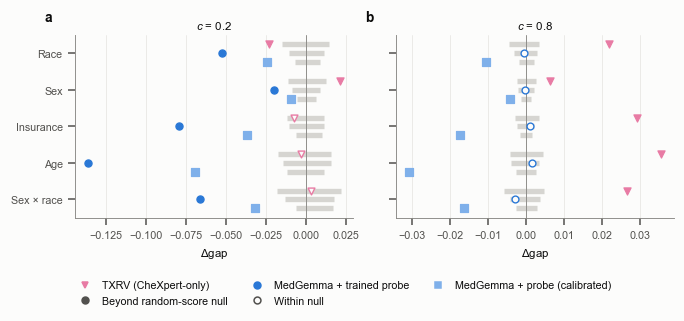

In [37]:
a = load("R7c_txrv_chexpert_only_cells").assign(system="txrv_chex")[["system", "attribute", "coverage", "dgap", "null_lo", "null_hi", "outside_null"]]
b = load("R7f_medgemma_trained_probe")
f = pd.concat([a, b], ignore_index=True)
f = f.assign(system=f.system.map(SYS), attribute=f.attribute.map(ATTR), coverage="$c$ = " + f.coverage.astype(str))
NEW = [SYS[s] for s in ["txrv_chex", "medgemma_probe", "medgemma_probe_calibrated"]]


def forest(data, **kw):
    ax = plt.gca()
    atts = list(ATTR.values())
    for off, name, mk in zip([-0.24, 0, 0.24], NEW, ["v", "o", "s"]):
        x = data[data.system == name].set_index("attribute").loc[atts]
        y = np.arange(len(atts)) + off
        ax.hlines(y, x.null_lo, x.null_hi, color="#d6d5d1", lw=3.5, zorder=1)
        on = x.outside_null.astype(bool).to_numpy()
        ax.scatter(x.dgap[on], y[on], marker=mk, color=SYS_COLOR[name], s=22, zorder=3, label=name)
        ax.scatter(x.dgap[~on], y[~on], marker=mk, facecolor=SURFACE, edgecolor=SYS_COLOR[name], s=20, lw=0.9, zorder=3)
    ax.axvline(0, color=MUTED, lw=0.6)
    ax.set_yticks(range(len(atts)), atts)
    ax.set_ylim(len(atts) - 0.5, -0.5)
    ax.grid(True, axis="x"); ax.grid(False, axis="y")


g = sns.FacetGrid(f, col="coverage", height=2.5, aspect=1.25, sharex=False)
g.map_dataframe(forest)
g.set_titles("{col_name}")
g.set_axis_labels(r"$\Delta$gap", "")
letter_panels(g.axes.flat)
bottom_legend(g, [dot_key(n, SYS_COLOR[n], SYS_MARKER[n]) for n in NEW]
           + filled_keys("Beyond random-score null", "Within null"), ncol=3)
save(g, "added_systems", f, ["general", "dYNd", "4Avf"])

## Figure R15. Task adaptation

Δgap at *c* = 0.2 before (open) and after (filled) task adaptation: per-finding recalibration and decision threshold fitted on a calibration half (a–c), and a trained probe on frozen MedGemma-4B image features (d).

saved figures/figR15_task_adaptation.png


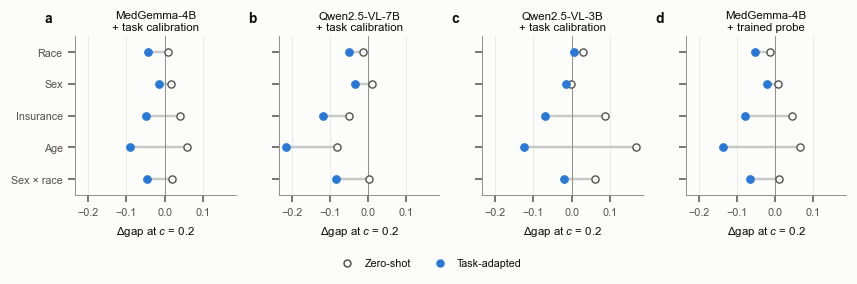

In [38]:
tc = load("R7d_task_calibration").query("system != 'llava15_7b'")
pr = load("R7f_medgemma_trained_probe").query("system == 'medgemma_probe' and coverage == 0.2")
r0 = load("R0_paper_random_null_25cells").query("system == 'medgemma_4b'")
rows = []
for _, r in tc.iterrows():
    name = f"{SYS[r.system]}\n+ task calibration"
    rows += [dict(system=name, attribute=ATTR[r.attribute], version="zero-shot", dgap=r.dgap20_zero_shot),
             dict(system=name, attribute=ATTR[r.attribute], version="task-adapted", dgap=r.dgap20_task_calibrated)]
for _, r in pr.merge(r0[["attribute", "A_observed"]], on="attribute").iterrows():
    rows += [dict(system="MedGemma-4B\n+ trained probe", attribute=ATTR[r.attribute], version="zero-shot", dgap=r.A_observed),
             dict(system="MedGemma-4B\n+ trained probe", attribute=ATTR[r.attribute], version="task-adapted", dgap=r.dgap)]
ta = pd.DataFrame(rows)


def dumbbell(data, **kw):
    ax = plt.gca()
    atts = list(ATTR.values())
    z = data[data.version == "zero-shot"].set_index("attribute").loc[atts]
    t = data[data.version == "task-adapted"].set_index("attribute").loc[atts]
    y = np.arange(len(atts))
    ax.hlines(y, z.dgap, t.dgap, color="#c9c8c4", lw=1.6, zorder=1)
    ax.scatter(z.dgap, y, facecolor=SURFACE, edgecolor=INK2, s=22, lw=0.9, zorder=3, label="Zero-shot")
    ax.scatter(t.dgap, y, color=PAL[0], s=24, zorder=3, label="Task-adapted")
    ax.axvline(0, color=MUTED, lw=0.6)
    ax.set_yticks(y, atts)
    ax.set_ylim(len(atts) - 0.5, -0.5)
    ax.grid(True, axis="x"); ax.grid(False, axis="y")


cols = [f"{SYS[s]}\n+ task calibration" for s in ["medgemma_4b", "qwen25vl_7b", "qwen25vl_3b"]] + ["MedGemma-4B\n+ trained probe"]
g = sns.FacetGrid(ta, col="system", col_order=cols, height=2.3, aspect=0.85)
g.map_dataframe(dumbbell)
g.set_titles("{col_name}")
g.set_axis_labels(r"$\Delta$gap at $c$ = 0.2", "")
letter_panels(g.axes.flat)
bottom_legend(g, [dot_key("Zero-shot", INK2, filled=False), dot_key("Task-adapted", PAL[0])])
save(g, "task_adaptation", ta, ["4Avf"])

## Figure R16. What the direction of redistribution depends on

Share of the submission's significant effects whose direction is unchanged under each kind of change; counts in parentheses.

saved figures/figR16_robustness_ledger.png


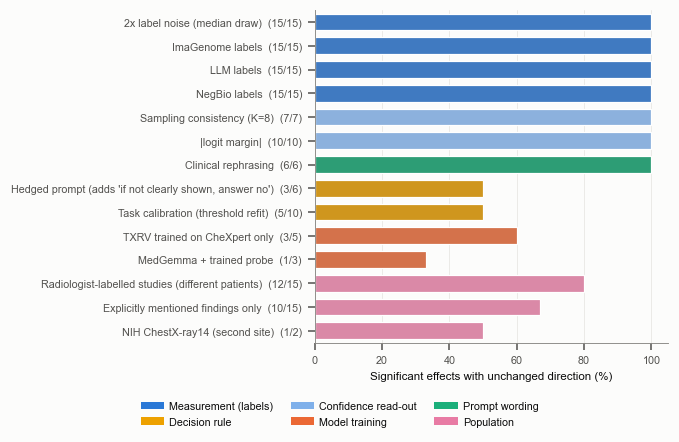

In [39]:
lb = load("R4b_robustness_ledger_by_perturbation").sort_values(["cls", "direction_kept_pct"], ascending=[True, False])
lb["change"] = (lb.perturbation.map(lambda t: t[0].upper() + t[1:]) + "  (" + lb.direction_kept.astype(int).astype(str)
                + "/" + lb.effects.astype(int).astype(str) + ")")
lb["kind of change"] = lb.cls.str.split(" ", n=1).str[1].str.capitalize()
kinds = list(dict.fromkeys(lb["kind of change"]))
fig, ax = plt.subplots(figsize=(6.2, 3.6))
CLS_COLOR = dict(zip(kinds, [PAL[0], "#7fb0ea", PAL[2], PAL[3], PAL[1], PAL[4]]))
sns.barplot(data=lb, y="change", x="direction_kept_pct", hue="kind of change", hue_order=kinds,
            palette=CLS_COLOR, dodge=False, width=0.7, ax=ax, legend=False)
ax.set(xlim=(0, 105), xlabel="Significant effects with unchanged direction (%)", ylabel="")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
bottom_legend(fig, [box_key(k, c) for k, c in CLS_COLOR.items()], ncol=3)
save(fig, "robustness_ledger", lb, ["general", "dYNd"])

## Figure R17. Robustness to the labels

Δgap at *c* = 0.2 with the submitted labels (horizontal axis) against (a) Chest ImaGenome labels, (b) labels extracted from the reports by a local LLM, (c) NegBio labels, (d) simulated label noise at twice the radiologist-measured rate (median draw) and (e) a separate cohort of radiologist-labelled studies (vertical axis). Shaded quadrants: direction unchanged. Filled markers: effects significant in the submission.

saved figures/figR17_label_robustness.png


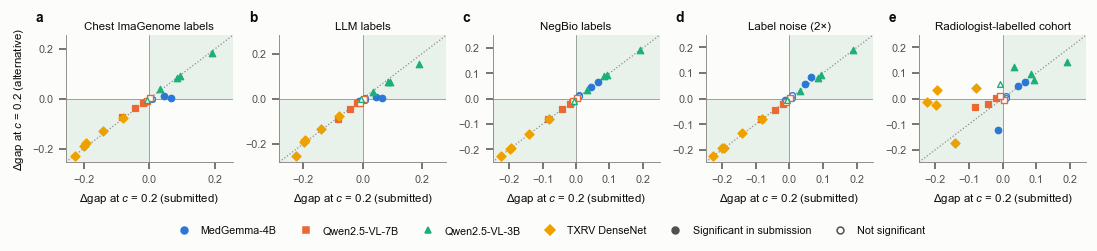

In [40]:
L = []
for _, r in load("R5d_imagenome_labels_dgap").iterrows():
    L.append(dict(labels="Chest ImaGenome labels", system=r.system, attribute=r.attribute, original=r.dgap20_paper, alternative=r.dgap20_imagenome, beyond=r.outside_null))
for _, r in load("R5f_llm_labels_dgap").iterrows():
    L.append(dict(labels="LLM labels", system=r.system, attribute=r.attribute, original=r.dgap20_paper, alternative=r.dgap20_llm, beyond=r.outside_null))
for _, r in load("R5g_negbio_consensus_explicit_labels").query("variant == 'negbio'").iterrows():
    L.append(dict(labels="NegBio labels", system=r.system, attribute=r.attribute, original=r.dgap20_paper, alternative=r.dgap20, beyond=r.outside_null))
for _, r in load("R5b_label_noise_simulation").query("scenario == 'doubled'").iterrows():
    L.append(dict(labels="Label noise (2×)", system=r.system, attribute=r.attribute, original=r.paper, alternative=r["median"], beyond=np.nan))
for _, r in load("R5h_radiologist_labelled_replication").query("coverage == 0.2").iterrows():
    L.append(dict(labels="Radiologist-labelled cohort", system=r.system, attribute=r.attribute, original=r.dgap_paper20, alternative=r.dgap, beyond=r.outside_null))
lab = pd.DataFrame(L).query("system in @HEADLINE").merge(SIG, on=["system", "attribute"])
lab["system"] = pd.Categorical(lab.system.map(SYS), [SYS[s] for s in HEADLINE])
lab = lab.sort_values("system")
LABEL_ORDER = ["Chest ImaGenome labels", "LLM labels", "NegBio labels", "Label noise (2×)", "Radiologist-labelled cohort"]
g = sns.FacetGrid(lab, col="labels", col_order=LABEL_ORDER, height=2.0, aspect=1.0, sharex=False, sharey=False)
g.map_dataframe(quadrant_scatter)
g.set_titles("{col_name}")
g.set_axis_labels(r"$\Delta$gap at $c$ = 0.2 (submitted)", r"$\Delta$gap at $c$ = 0.2 (alternative)")
letter_panels(g.axes.flat)
bottom_legend(g, system_keys(HEADLINE) + filled_keys("Significant in submission", "Not significant"))
save(g, "label_robustness", lab, ["4Avf", "dYNd"])

## Figure R18. Probability mass outside the yes/no tokens

Next-token probability mass outside {yes, no} at the first answer position (race-stratified 25% sample; 29,457 evaluations per model): median, interquartile range, 5th percentile of the yes/no mass, and the lowest yes/no mass of any evaluation. The dotted line marks 1%.

saved figures/figR18_token_mass.png


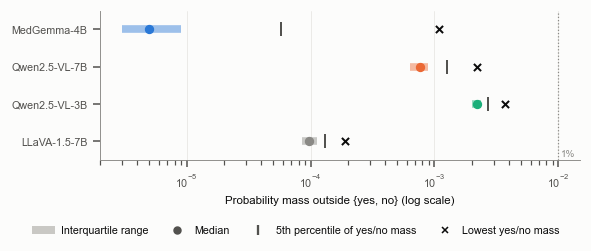

In [41]:
tm = load("R6a_token_mass_yes_no")
order = ["medgemma_4b", "qwen25vl_7b", "qwen25vl_3b", "llava15_7b"]
plot = tm.set_index("system").loc[order].reset_index()
fig, ax = plt.subplots(figsize=(5.4, 2.0))
for i, r in plot.iterrows():
    col = SYS_COLOR[SYS[r.system]]
    ax.hlines(i, 1 - r.mass_q75, 1 - r.mass_q25, color=col, lw=5, alpha=0.45)
    ax.scatter(1 - r.mass_median, i, color=col, s=28, zorder=3, label="median" if i == 0 else None)
    ax.scatter(1 - r.mass_p05, i, marker="|", color=INK2, s=80, zorder=3, label="5th percentile of mass" if i == 0 else None)
    ax.scatter(1 - r.mass_min, i, marker="x", color=INK, s=22, zorder=3, label="worst evaluation" if i == 0 else None)
ax.set_xscale("log")
ax.axvline(0.01, color=MUTED, ls=":", lw=0.8)
ax.text(0.0105, len(order) - 0.6, "1%", color=MUTED, fontsize=6.5)
ax.set_yticks(range(len(order)), [SYS[s] for s in order])
ax.set_ylim(len(order) - 0.5, -0.5)
ax.set_xlabel("Probability mass outside {yes, no} (log scale)")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
bottom_legend(fig, [box_key("Interquartile range", "#c9c8c4"), dot_key("Median", INK2),
                 Line2D([], [], ls="", marker="|", ms=7, mew=1.5, color=INK2, label="5th percentile of yes/no mass"),
                 dot_key("Lowest yes/no mass", INK, "x")])
save(fig, "token_mass", plot, ["X8Ma", "4Avf"])

## Figure R19. Alternative confidence measures

Δgap at *c* = 0.2 with the submitted confidence (horizontal axis) against (a) the logit margin, (b) sampling consistency (*K* = 8, *T* = 0.7), (c) a reworded prompt and (d) a prompt with an added decision rule (vertical axis); (c, d) use the race-stratified 25% sample. Shaded quadrants: direction unchanged. Filled markers: effects significant in the submission. MedGemma-4B is omitted from (b) because its eight samples agree on 97.8% of evaluations.

saved figures/figR19_confidence_alternatives.png


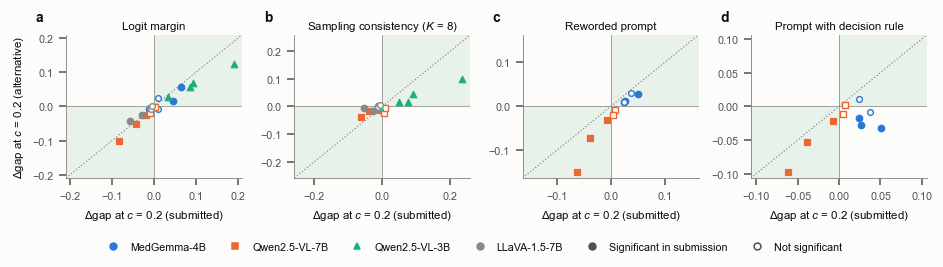

In [42]:
m1 = (load("R6d_logit_margin_confidence").rename(columns={"dgap20_confidence": "original", "dgap20_abs_margin": "alternative"})
        .assign(alternative_score="Logit margin"))
m2 = (load("R6b_sampling_consistency_cells").query("run == 'T0.7' and system != 'medgemma_4b'")
        .rename(columns={"dgap20_logit": "original", "dgap20_consistency": "alternative"})
        .assign(alternative_score="Sampling consistency ($K$ = 8)"))
PROMPT = {"clinical": "Reworded prompt", "hedged": "Prompt with decision rule"}
m3 = pd.DataFrame([dict(system=r.system, attribute=a, original=r[f"dgap20_base_{a}"], alternative=r[f"dgap20_alt_{a}"],
                        alternative_score=PROMPT[r.prompt])
                   for _, r in load("R6c_prompt_variants_five_race").iterrows() for a in ATTR])
alt = (pd.concat([m1, m2, m3], ignore_index=True)[["system", "attribute", "alternative_score", "original", "alternative"]]
         .merge(SIG, on=["system", "attribute"]))
alt["system"] = pd.Categorical(alt.system.map(SYS), [SYS[s] for s in HEADLINE + ["llava15_7b"]])
alt = alt.sort_values("system")
g = sns.FacetGrid(alt, col="alternative_score", col_order=["Logit margin", "Sampling consistency ($K$ = 8)", *PROMPT.values()],
                  height=2.15, aspect=1.0, sharex=False, sharey=False)
g.map_dataframe(quadrant_scatter)
g.set_titles("{col_name}")
g.set_axis_labels(r"$\Delta$gap at $c$ = 0.2 (submitted)", r"$\Delta$gap at $c$ = 0.2 (alternative)")
letter_panels(g.axes.flat)
bottom_legend(g, system_keys(HEADLINE[:3] + ["llava15_7b"]) + filled_keys("Significant in submission", "Not significant"))
save(g, "confidence_alternatives", alt, ["X8Ma"])

## Figure R20. Two-channel decomposition

Δgap at *c* = 0.2 by system (a–d): observed, with calibration equalised across groups (distribution shift only), and with the confidence distribution equalised (calibration disparity only). The decomposition is descriptive, not causal.

saved figures/figR20_decomposition.png


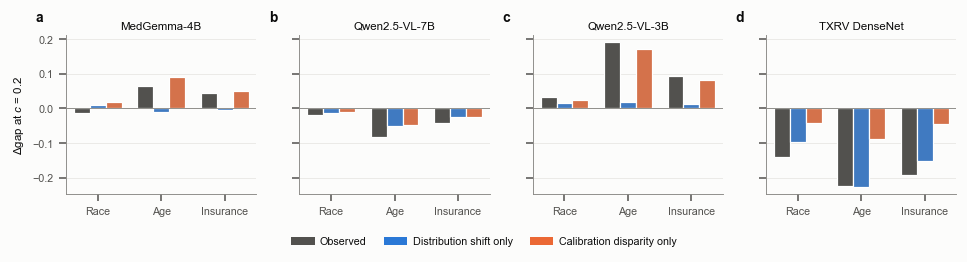

In [43]:
dc = load("R9a_two_channel_decomposition").query("coverage == 0.2 and system != 'llava15_7b'")
COMP = {"dgap_obs": "Observed", "dgap_cal_parity": "Distribution shift only", "dgap_dist_parity": "Calibration disparity only"}
plot = dc.melt(id_vars=["system", "attribute"], value_vars=list(COMP), var_name="component")
plot = plot.assign(component=plot.component.map(COMP), system=plot.system.map(SYS), attribute=plot.attribute.map(ATTR))
g = sns.catplot(data=plot, kind="bar", x="attribute", y="value", hue="component", hue_order=list(COMP.values()),
                palette=[INK2, PAL[0], PAL[1]], col="system", col_order=[SYS[s] for s in HEADLINE],
                order=["Race", "Age", "Insurance"], height=2.1, aspect=1.05, width=0.75, legend=False)
g.set_titles("{col_name}")
g.set_axis_labels("", r"$\Delta$gap at $c$ = 0.2")
for ax in g.axes.flat:
    ax.axhline(0, color=MUTED, lw=0.6)
letter_panels(g.axes.flat)
bottom_legend(g, [box_key(k, c) for k, c in zip(COMP.values(), [INK2, PAL[0], PAL[1]])])
save(g, "decomposition", plot, ["X8Ma", "4Avf"])

## Figure R21. Image-blind controls

Detection AUROC within finding (a) and failure-prediction AUROC (b) with the real image, a blank image and another patient's image. The dotted line marks chance.

saved figures/figR21_image_blind_controls.png


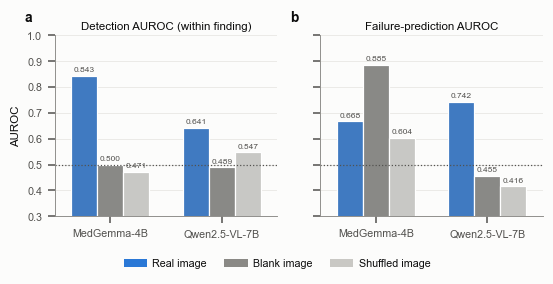

In [44]:
ib = load("R10_image_blind_controls")
MODE = {"real image": "Real image", "img-blank": "Blank image", "img-shuffled": "Shuffled image"}
MET = {"within_finding_auroc": "Detection AUROC (within finding)", "fail_auroc": "Failure-prediction AUROC"}
plot = ib.melt(id_vars=["system", "image_mode"], value_vars=list(MET), var_name="metric")
plot = plot.assign(metric=plot.metric.map(MET), image_mode=plot.image_mode.map(MODE), system=plot.system.map(SYS))
g = sns.catplot(data=plot, kind="bar", x="system", y="value", hue="image_mode", hue_order=list(MODE.values()),
                palette=[PAL[0], MUTED, "#c9c8c4"], col="metric", col_order=list(MET.values()), height=2.3, aspect=1.1, width=0.7,
                legend=False)
g.set_titles("{col_name}")
g.set_axis_labels("", "AUROC")
g.set(ylim=(0.3, 1.0))
for ax in g.axes.flat:
    ax.axhline(0.5, color=INK2, ls=":", lw=0.8)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", padding=2, fontsize=5.5, color=INK2)
letter_panels(g.axes.flat)
bottom_legend(g, [box_key(m, c) for m, c in zip(MODE.values(), [PAL[0], MUTED, "#c9c8c4"])])
save(g, "image_blind_controls", plot, ["general", "4Avf"])